# Tome 0, Chapter 6: Integrals and Taylor Formulas (Python companion)

Exercises first, solutions at the end. Computer-science threads: **numerical integration** and its error rates,
**Monte Carlo** in high dimension, and a classic floating-point trap with Taylor series.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(0)

## Exercises

**P6.1 (★) Wallis, numerically.** Compute $W_n$ by the recurrence for $n \le 1000$ and check $nW_nW_{n-1} = \pi/2$ and $W_n\sqrt{2n/\pi} \to 1$. How many factors of Wallis' product are needed for 3 correct digits of $\pi$?

In [2]:
# Your code here


**P6.2 (★★) CS application: quadrature rules.** Implement the composite trapezoid and Simpson rules, and Gauss–Legendre quadrature (`np.polynomial.legendre.leggauss`). Integrate $e^{-x^2}$ on $[0, 2]$ with $n$ points and plot the error against $n$ on a log–log scale. Read off the slopes: the trapezoid error is $O(n^{-2})$, Simpson $O(n^{-4})$, Gauss faster than any power.

In [3]:
# Your code here


**P6.3 (★★) CS application: Monte Carlo and the curse of dimension.** The volume of the unit ball in $\mathbb R^d$ is $V_d = \frac{\pi^{d/2}}{\Gamma(d/2+1)}$ (Tome 4 proves it with Wallis-type integrals). Estimate $V_d$ by sampling uniform points in $[-1,1]^d$ for $d = 2, 5, 10, 15$. Why does the method collapse as $d$ grows, and what does that say about the ball?

In [4]:
# Your code here


**P6.4 (★★) A Taylor trap.** Compute $e^{-20}$ by summing $\sum_k \frac{(-20)^k}{k!}$ in float64. Compare with `math.exp(-20)`. Explain the disaster, and fix it with one line.

In [5]:
# Your code here


**P6.5 (★★★) Squeezing the Gaussian.** Plot the two bounds $\sqrt n\,W_{2n+1} \le \int_0^\infty e^{-x^2} \le \sqrt n\,W_{2n-2}$ of Exercise 6.7 against $n$, together with $\sqrt\pi/2$.

In [6]:
# Your code here


---
## Solutions

### P6.1

In [7]:
W = [math.pi / 2, 1.0]
for n in range(2, 1001):
    W.append((n - 1) / n * W[n - 2])
assert all(math.isclose(n * W[n] * W[n - 1], math.pi / 2) for n in range(1, 1001))
print("W_n * sqrt(2n/pi) at n = 1000:", W[1000] * math.sqrt(2000 / math.pi))

prod, p = 1.0, 0
while abs(2 * prod - math.pi) >= 0.0005:
    p += 1
    prod *= (2 * p) ** 2 / ((2 * p - 1) * (2 * p + 1))
print(f"{p} factors give 2 * product = {2 * prod:.5f}")

W_n * sqrt(2n/pi) at n = 1000: 0.9997500312890546
1571 factors give 2 * product = 3.14109


Wallis' product converges slowly: the error after $p$ factors is about $\frac{\pi}{4p}$, hence about 1600 factors for 3 digits.

### P6.2

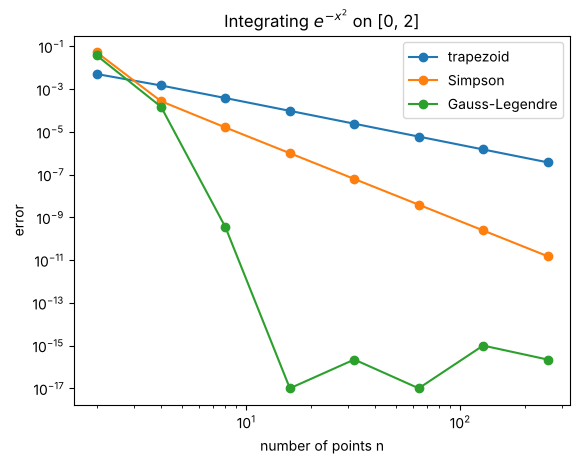

In [8]:
f = lambda x: np.exp(-x**2)
a, b = 0.0, 2.0
exact = math.sqrt(math.pi) / 2 * math.erf(2)

def trapezoid(n):
    x = np.linspace(a, b, n + 1)
    return (b - a) / n * (f(x).sum() - (f(a) + f(b)) / 2)

def simpson(n):              # n even
    x = np.linspace(a, b, n + 1)
    w = np.ones(n + 1); w[1:-1:2] = 4; w[2:-1:2] = 2
    return (b - a) / (3 * n) * (w * f(x)).sum()

def gauss(n):
    t, w = np.polynomial.legendre.leggauss(n)
    return (b - a) / 2 * (w * f((b - a) / 2 * t + (a + b) / 2)).sum()

ns = [2, 4, 8, 16, 32, 64, 128, 256]
for rule, name in [(trapezoid, "trapezoid"), (simpson, "Simpson"), (gauss, "Gauss-Legendre")]:
    errs = [max(abs(rule(n) - exact), 1e-17) for n in ns]
    plt.loglog(ns, errs, "o-", label=name)
plt.xlabel("number of points n"); plt.ylabel("error"); plt.legend(); plt.title(r"Integrating $e^{-x^2}$ on [0, 2]"); plt.show()

The slopes are $-2$ and $-4$; Gauss–Legendre with $n$ points is exact on polynomials of degree $2n-1$, so for a smooth integrand its error falls faster than any power of $n$ and reaches machine precision with about 12 points.

### P6.3

In [9]:
N = 1_000_000
for d in [2, 5, 10, 15]:
    pts = rng.uniform(-1, 1, size=(N, d))
    inside = (np.einsum("ij,ij->i", pts, pts) <= 1).mean()
    est = inside * 2**d
    true = math.pi ** (d / 2) / math.gamma(d / 2 + 1)
    print(f"d = {d:2d}: estimate {est:.4f}, true {true:.4f}, fraction of cube inside ball {inside:.2e}")

d =  2: estimate 3.1416, true 3.1416, fraction of cube inside ball 7.85e-01
d =  5: estimate 5.2705, true 5.2638, fraction of cube inside ball 1.65e-01


d = 10: estimate 2.4945, true 2.5502, fraction of cube inside ball 2.44e-03


d = 15: estimate 0.3932, true 0.3814, fraction of cube inside ball 1.20e-05


The fraction of the cube occupied by the ball, $V_d/2^d$, tends to $0$ extremely fast (about $10^{-5}$ for $d = 15$). With a million samples only a handful land inside, so the relative error explodes. In high dimension, almost all the volume of a cube is in its corners, a fact that haunts machine learning.

### P6.4

In [10]:
s, term = 0.0, 1.0
for k in range(1, 200):
    s += term
    term *= -20 / k
print("naive series:", s)
print("math.exp    :", math.exp(-20))
t, e20 = 1.0, 0.0
for k in range(1, 200):
    e20 += t
    t *= 20 / k
print("1 / (series for e^20):", 1 / e20)

naive series: 6.147561828914626e-09
math.exp    : 2.061153622438558e-09
1 / (series for e^20): 2.061153622438557e-09


The terms reach $20^{20}/20! \approx 4\times10^7$ in size, alternate in sign, and cancel down to $2\times10^{-9}$. Float64 has about 16 significant digits, so the rounding errors on the big terms ($\sim 10^{-9}$) are as large as the answer. The fix: compute $e^{20}$, whose series has only positive terms, and invert it.

### P6.5

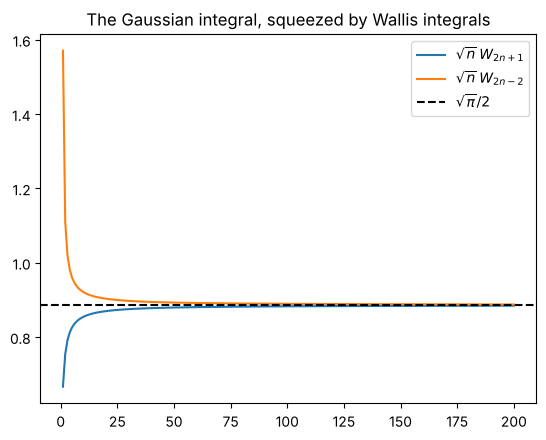

In [11]:
W = [math.pi / 2, 1.0]
for n in range(2, 2 * 200 + 2):
    W.append((n - 1) / n * W[n - 2])
ns = np.arange(1, 201)
low = [math.sqrt(n) * W[2 * n + 1] for n in ns]
high = [math.sqrt(n) * W[2 * n - 2] for n in ns]
plt.plot(ns, low, label=r"$\sqrt{n}\,W_{2n+1}$"); plt.plot(ns, high, label=r"$\sqrt{n}\,W_{2n-2}$")
plt.axhline(math.sqrt(math.pi) / 2, ls="--", c="k", label=r"$\sqrt{\pi}/2$")
plt.legend(); plt.title("The Gaussian integral, squeezed by Wallis integrals"); plt.show()